# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [1]:
import pandas as pd
import plotly.express as px

## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer:Where were magnitude 4.0 or greater earthquakes recorded worldwide during 2025, and how did the monthly number of recorded events change? A point map will show locations, and a monthly count line chart will show timing. Considering both is useful because a yearly map alone hides changes over time, while monthly counts alone hide where events occurred.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer:Dataset: USGS Earthquake Catalog, worldwide events with reported magnitude 4.0 or greater, downloaded for the 2025 analysis.

Publisher: U.S. Geological Survey (USGS).
Source: https://earthquake.usgs.gov/earthquakes/search/
CSV field definitions: https://earthquake.usgs.gov/data/comcat/data-eventterms.php
Access date: November 15, 2026.
Saved file: data/query (1).csv.

The original CSV is preserved. A separate analysis subset retains only earthquakes occurring during calendar year 2025 UTC with magnitude at least 4.0. No station lookup or local boundary file is used; the map uses the supplied latitude and longitude.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:One row represents one event recorded in the USGS earthquake catalog. The selected analysis contains 18,302 earthquakes worldwide, occurring from January 1 through December 31, 2025 UTC, with reported magnitudes of at least 4.0. Locations are supplied as latitude and longitude. USGS compiles event information from seismic monitoring networks and contributing agencies; these are cataloged detections rather than a random sample of locations. The downloaded file also contained records outside the selected criteria, which were excluded from the analysis subset while preserving the original file.

In [2]:
earthquakes_df = pd.read_csv("data/query (1).csv")

earthquakes_df["time"] = pd.to_datetime(
    earthquakes_df["time"], utc=True, errors="coerce"
)

earthquakes_df.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2025-01-01 00:13:22.650000+00:00,12.7441,143.6244,35.000,4.2,mb,12.0,160.0,1.474,0.76,...,2025-03-17T21:33:57.040Z,"127 km WSW of Merizo Village, Guam",earthquake,12.60,1.974,0.199,7.0,reviewed,us,us
1,2025-01-01 01:00:50.839000+00:00,34.6287,16.5823,10.000,4.0,mb,12.0,246.0,3.361,1.19,...,2025-03-17T21:33:57.040Z,"228 km SE of Marsaskala, Malta",earthquake,7.78,2.005,0.211,6.0,reviewed,us,us
2,2025-01-01 01:07:10.492000+00:00,-5.9077,128.8869,277.355,4.4,mb,19.0,81.0,1.709,0.89,...,2025-03-17T21:33:57.040Z,"256 km SSE of Ambon, Indonesia",earthquake,10.20,12.427,0.203,7.0,reviewed,us,us
3,2025-01-01 01:46:59.538000+00:00,-3.8682,151.6536,10.000,4.7,mb,39.0,99.0,0.557,0.86,...,2025-03-17T21:33:58.040Z,"67 km WNW of Rabaul, Papua New Guinea",earthquake,6.86,1.901,0.108,26.0,reviewed,us,us
4,2025-01-01 02:00:06.918000+00:00,-3.8521,151.6207,10.000,4.5,mb,36.0,98.0,0.591,0.98,...,2025-03-17T21:33:58.040Z,"71 km WNW of Rabaul, Papua New Guinea",earthquake,7.80,1.901,0.116,22.0,reviewed,us,us


In [3]:
earthquakes_df.tail()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
18345,2026-01-01 21:35:02.491000+00:00,-18.6924,168.6565,139.060,5.2,mb,42.0,79.0,3.514,0.92,...,2026-04-07T22:11:50.040Z,"111 km SSE of Port-Vila, Vanuatu",earthquake,8.25,5.759,0.067,73.0,reviewed,us,us
18346,2026-01-01 22:13:04.383000+00:00,17.7176,145.9978,120.325,4.5,mb,48.0,83.0,2.471,0.83,...,2026-04-07T22:11:59.040Z,"278 km N of Saipan, Northern Mariana Islands",earthquake,11.60,7.549,0.077,53.0,reviewed,us,us
18347,2026-01-01 22:49:46.878000+00:00,-21.6906,-68.5036,131.526,4.7,mb,45.0,40.0,0.694,1.02,...,2026-04-07T22:11:50.040Z,"57 km SSW of Ollagüe, Chile",earthquake,6.48,5.516,0.097,33.0,reviewed,us,us
18348,2026-01-01 23:27:18.120000+00:00,13.2479,146.0834,10.000,4.8,mb,39.0,82.0,1.994,0.84,...,2026-04-07T22:11:59.040Z,"133 km ESE of Yigo Village, Guam",earthquake,11.21,1.885,0.094,37.0,reviewed,us,us
18349,2026-01-01 23:30:51.522000+00:00,-15.4795,-76.3908,10.000,4.2,mb,18.0,172.0,3.499,0.64,...,2026-04-07T22:11:50.040Z,"132 km W of San Juan, Peru",earthquake,11.61,1.974,0.236,5.0,reviewed,us,us


In [4]:
earthquakes_df.shape

(18350, 22)

In [5]:
earthquakes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18350 entries, 0 to 18349
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   time             18350 non-null  datetime64[us, UTC]
 1   latitude         18350 non-null  float64            
 2   longitude        18350 non-null  float64            
 3   depth            18350 non-null  float64            
 4   mag              18350 non-null  float64            
 5   magType          18350 non-null  str                
 6   nst              18282 non-null  float64            
 7   gap              18278 non-null  float64            
 8   dmin             18277 non-null  float64            
 9   rms              18350 non-null  float64            
 10  net              18350 non-null  str                
 11  id               18350 non-null  str                
 12  updated          18350 non-null  str                
 13  place            18350 non-

In [6]:
earthquakes_df.isna().sum()

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                68
gap                72
dmin               73
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError    71
depthError          0
magError           97
magNst             71
status              0
locationSource      0
magSource           0
dtype: int64

In [7]:
earthquakes_2025_df = earthquakes_df.loc[
    (earthquakes_df["time"] >= pd.Timestamp("2025-01-01", tz="UTC"))
    & (earthquakes_df["time"] < pd.Timestamp("2026-01-01", tz="UTC"))
    & (earthquakes_df["mag"] >= 4)
    & (earthquakes_df["type"] == "earthquake")
].copy()

print("Original records:", len(earthquakes_df))
print("Selected 2025 earthquakes:", len(earthquakes_2025_df))
print("Records excluded:", len(earthquakes_df) - len(earthquakes_2025_df))

display(earthquakes_2025_df["time"].agg(["min", "max"]))
display(earthquakes_2025_df["mag"].agg(["min", "max"]))

display(
    earthquakes_2025_df[
        ["time", "latitude", "longitude", "mag"]
    ].isna().sum()
)

Original records: 18350
Selected 2025 earthquakes: 18302
Records excluded: 48


min   2025-01-01 00:13:22.650000+00:00
max   2025-12-31 23:52:11.327000+00:00
Name: time, dtype: datetime64[us, UTC]

min    4.0
max    8.8
Name: mag, dtype: float64

time         0
latitude     0
longitude    0
mag          0
dtype: int64

In [8]:
earthquakes_2025_df.info()

<class 'pandas.DataFrame'>
Index: 18302 entries, 0 to 18304
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   time             18302 non-null  datetime64[us, UTC]
 1   latitude         18302 non-null  float64            
 2   longitude        18302 non-null  float64            
 3   depth            18302 non-null  float64            
 4   mag              18302 non-null  float64            
 5   magType          18302 non-null  str                
 6   nst              18235 non-null  float64            
 7   gap              18233 non-null  float64            
 8   dmin             18232 non-null  float64            
 9   rms              18302 non-null  float64            
 10  net              18302 non-null  str                
 11  id               18302 non-null  str                
 12  updated          18302 non-null  str                
 13  place            18302 non-null 

In [9]:
earthquakes_2025_df.isna().sum()

time                0
latitude            0
longitude           0
depth               0
mag                 0
magType             0
nst                67
gap                69
dmin               70
rms                 0
net                 0
id                  0
updated             0
place               0
type                0
horizontalError    70
depthError          0
magError           96
magNst             70
status              0
locationSource      0
magSource           0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type str | Missing values 0 |
| --- | --- | --- | --- | --- |
|time |Event time in UTC |Temporal |datetime64[us, UTC] |0 |
|latitude | Latitude in decimal dgrees | Quantitative spatial coordinate|float64 |0 |
|longitude | Longitude in decimal degrees | Quiantitative | float64 | 0 |
|mag | Reported earthquake magnitude | Quantitative | float64 | 0 |
|type | Event classification; retained "earthquake" | Categorical | str | 0 |
|magType | Methode/type of magnitude reproted | Categorical | str | 0 |
|depth | Event depth in kilometers | Quantitative | float | 0 |
|place | Catalog location description | Quantitative | float64 | 0 | 

Use quantitative, categorical, or temporal for feature type.

Your answer:

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:I will analyze recorded earthquakes worldwide with magnitude at least 4.0 during calendar year 2025, using UTC dates. Latitude and longitude locate events, while magnitude, magnitude type, depth in kilometers, and place descriptions provide map and hover information. I will count events by UTC calendar month without dividing them into geographic regions. These are catalog event counts, not rates or measures of risk. Required times, coordinates, and magnitudes have no missing values; missing values in unused fields do not require exclusions.

In [10]:
earthquakes_2025_df = earthquakes_2025_df.sort_values("time").copy()

earthquakes_2025_df["month"] = (
    earthquakes_2025_df["time"].dt.strftime("%Y-%m")
)

monthly_counts_df = (
    earthquakes_2025_df.groupby("month")
    .size()
    .reindex(
        pd.period_range("2025-01", "2025-12", freq="M").astype(str),
        fill_value=0
    )
    .rename_axis("month")
    .reset_index(name="earthquake_count")
)

print("Original records:", len(earthquakes_df))
print("Retained events:", len(earthquakes_2025_df))
print("Excluded records:", len(earthquakes_df) - len(earthquakes_2025_df))
print(
    "Coordinates outside valid bounds:",
    (
        ~earthquakes_2025_df["latitude"].between(-90, 90)
        | ~earthquakes_2025_df["longitude"].between(-180, 180)
    ).sum()
)

display(monthly_counts_df)
print("Sum of monthly counts:", monthly_counts_df["earthquake_count"].sum())

Original records: 18350
Retained events: 18302
Excluded records: 48
Coordinates outside valid bounds: 0


,month,earthquake_count
0,2025-01,1413
1,2025-02,1394
2,2025-03,1178
3,2025-04,1316
4,2025-05,1228
5,2025-06,1156
6,2025-07,2684
7,2025-08,2222
8,2025-09,1604
9,2025-10,1509


Sum of monthly counts: 18302


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:The combined date, magnitude, and event-type filters excluded 48 of the 18,350 downloaded records, leaving 18,302 earthquakes. Before aggregation, each row represents one cataloged event. After aggregation, each row in monthly_counts_df represents one UTC calendar month and its recorded earthquake count. The map uses coordinates directly, so no geographic identifier lookup is required.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:

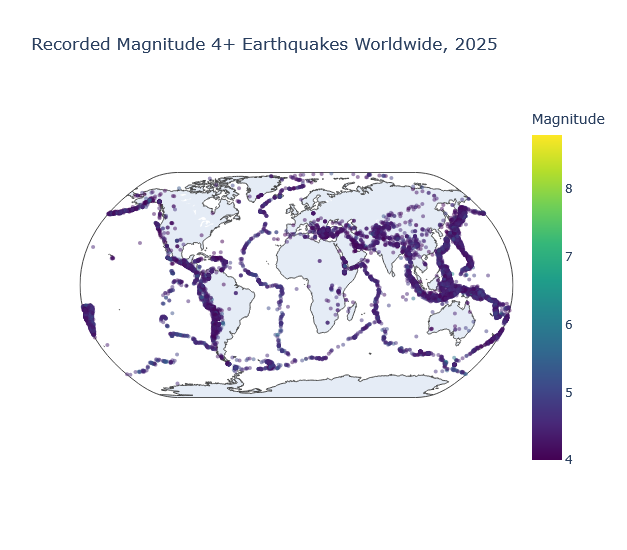

In [11]:
fig = px.scatter_geo(
    earthquakes_2025_df,
    lat="latitude",
    lon="longitude",
    color="mag",
    hover_name="place",
    hover_data={
        "time": True,
        "magType": True,
        "depth": True,
        "latitude": ":.2f",
        "longitude": ":.2f"
    },
    color_continuous_scale="Viridis",
    labels={
        "mag": "Magnitude",
        "magType": "Magnitude type",
        "depth": "Depth (km)",
        "time": "Time (UTC)"
    },
    title="Recorded Magnitude 4+ Earthquakes Worldwide, 2025"
)

fig.update_traces(marker=dict(size=4, opacity=0.5))
fig.update_geos(projection_type="natural earth", showcoastlines=True)
fig.update_layout(height=550)
fig.show()

In [13]:
earthquakes_2025_df.nlargest(1, "mag")[
    ["place", "time", "mag", "magType", "depth"]
]

,place,time,mag,magType,depth
9383,"2025 Kamchatka Peninsula, Russia Earthquake",2025-07-29 23:24:52.483000+00:00,8.8,mww,35.0


**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:Figure 1 maps 18,302 recorded magnitude 4.0 or greater earthquakes worldwide during 2025. Events are clustered rather than evenly distributed, with prominent bands around the Pacific margins and across ocean basins. Color represents reported magnitude. The largest event in this dataset is labeled “2025 Kamchatka Peninsula, Russia Earthquake,” recorded on July 29, 2025 at 23:24:52 UTC, with magnitude 8.8 (mww) and depth 35 km. Overlapping markers can hide events, so visible dots do not provide exact regional counts.

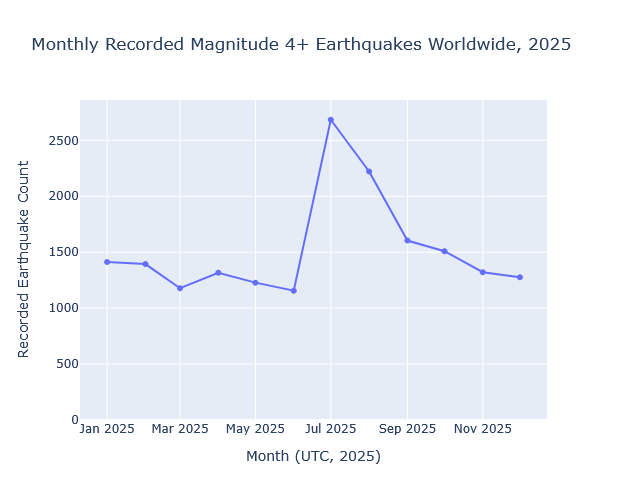

In [12]:
fig = px.line(
    monthly_counts_df.sort_values("month"),
    x="month",
    y="earthquake_count",
    markers=True,
    labels={
        "month": "Month (UTC, 2025)",
        "earthquake_count": "Recorded Earthquake Count"
    },
    title="Monthly Recorded Magnitude 4+ Earthquakes Worldwide, 2025"
)

fig.update_yaxes(rangemode="tozero")
fig.update_layout(height=500)
fig.show()

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:Figure 2 shows how worldwide recorded magnitude 4+ earthquake counts changed by UTC calendar month during 2025. July had the highest count at 2,684 events, compared with the lowest count of 1,156 in June. August remained elevated at 2,222 events, followed by declining monthly counts through December.

Figure 1 shows geographic clustering across the year, while Figure 2 reveals the timing of changes in global counts. Together they show where events were recorded and when counts increased. However, the global line chart does not identify which regions contributed to the July peak or establish its cause.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [14]:
for month in ["2025-06", "2025-07"]:
    source_count = (
        earthquakes_2025_df["time"].dt.strftime("%Y-%m") == month
    ).sum()

    plotted_count = monthly_counts_df.loc[
        monthly_counts_df["month"] == month, "earthquake_count"
    ].iloc[0]

    print(
        month,
        "Source count:", source_count,
        "Chart count:", plotted_count,
        "Match:", source_count == plotted_count
    )

print(
    "Months in chronological order:",
    monthly_counts_df["month"].is_monotonic_increasing
)

display(
    earthquakes_2025_df.nlargest(1, "mag")[
        ["place", "time", "latitude", "longitude", "mag"]
    ]
)

2025-06 Source count: 1156 Chart count: 1156 Match: True
2025-07 Source count: 2684 Chart count: 2684 Match: True
Months in chronological order: True


,place,time,latitude,longitude,mag
9383,"2025 Kamchatka Peninsula, Russia Earthquake",2025-07-29 23:24:52.483000+00:00,52.4948,160.2395,8.8


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:I recalculated June’s 1,156 events and July’s 2,684 events directly from the selected earthquake records. Both matched the monthly summaries used by the chart. The months were in chronological order, confirming that the July peak was not caused by incorrect ordering. I also inspected the magnitude 8.8 event’s source record: July 29, 2025 at 23:24:52 UTC, latitude 52.4948 and longitude 160.2395, near Kamchatka. Its coordinates are consistent with the mapped region.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:My question was where magnitude 4+ earthquakes were recorded worldwide during 2025 and how monthly counts changed. The map shows clustered bands around the Pacific margins and across ocean basins, with fewer plotted events across many continental interiors. One notable event was the magnitude 8.8 Kamchatka earthquake recorded on July 29 UTC. Worldwide monthly counts rose from 1,156 in June to 2,684 in July, then declined to 1,277 by December. The figures establish geographic clustering and temporal variation, but do not identify which regions caused the global monthly peak.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:First, catalog counts depend on detection, reporting, and the magnitude threshold. They are not population-adjusted risk measures, and this one-year comparison does not establish a long-term trend or explain the July peak.

Second, map markers overlap and summarize the entire year, making exact regional counts and regional timing difficult to compare. The line chart clearly shows monthly global changes but hides their geographic sources. A regional-by-month analysis would be needed to connect particular places to the peak.

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: How did monthly precipitation totals differ among the Seattle–Tacoma, Miami, and Phoenix Sky Harbor airport weather stations during 2025? A station map will show where the measurements were collected, and a monthly line chart will show when precipitation differed. Both space and time matter because annual totals can hide seasonal differences.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer:Dataset: GHCN-Daily / Daily Summaries precipitation records for Seattle–Tacoma, Miami International, and Phoenix Sky Harbor airport stations during 2025.

Publisher: NOAA National Centers for Environmental Information (NCEI).
Source: https://www.ncei.noaa.gov/access/search/data-search/daily-summaries/
Data dictionary: https://www.ncei.noaa.gov/pub/data/cdo/documentation/GHCND_documentation.pdf

Saved file: data/Weather_2025.csv. The download requested metric units, station names, station coordinates, and precipitation attributes. Coordinates are included in the CSV, so no separate location lookup or boundary file is needed.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer:One row represents one station’s daily record. The requested coverage is January 1–December 31, 2025, for Seattle–Tacoma (USW00024233), Miami International (USW00012839), and Phoenix Sky Harbor (USW00023183). PRCP records daily precipitation in millimeters under the selected metric download settings. NOAA compiles station observations into GHCN-Daily and applies quality checks. I will verify the actual date coverage, missing measurements, and flags before calculating monthly totals.

In [15]:
weather_df = pd.read_csv(
    "data/Weather_2025.csv",
    dtype={"STATION": str}
)

weather_df["DATE"] = pd.to_datetime(
    weather_df["DATE"], errors="coerce"
)

In [16]:
weather_df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,PRCP_ATTRIBUTES
0,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-01-01,1.0,",,W,2400"
1,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-01-02,1.3,",,W,2400"
2,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-01-03,12.2,",,W,2400"
3,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-01-04,6.1,",,W,2400"
4,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-01-05,0.0,"T,,W,2400"


In [17]:
weather_df.tail()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,PRCP_ATTRIBUTES
1090,USW00023183,"PHOENIX AIRPORT, AZ US",33.4278,-112.00365,339.2,2025-12-27,0.0,",,1,2400"
1091,USW00023183,"PHOENIX AIRPORT, AZ US",33.4278,-112.00365,339.2,2025-12-28,0.0,",,1,2400"
1092,USW00023183,"PHOENIX AIRPORT, AZ US",33.4278,-112.00365,339.2,2025-12-29,0.0,",,1,2400"
1093,USW00023183,"PHOENIX AIRPORT, AZ US",33.4278,-112.00365,339.2,2025-12-30,0.0,",,1,2400"
1094,USW00023183,"PHOENIX AIRPORT, AZ US",33.4278,-112.00365,339.2,2025-12-31,0.0,"T,,1,2400"


In [18]:
weather_df.shape

(1095, 8)

In [19]:
weather_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   STATION          1095 non-null   str           
 1   NAME             1095 non-null   str           
 2   LATITUDE         1095 non-null   float64       
 3   LONGITUDE        1095 non-null   float64       
 4   ELEVATION        1095 non-null   float64       
 5   DATE             1095 non-null   datetime64[us]
 6   PRCP             1094 non-null   float64       
 7   PRCP_ATTRIBUTES  1094 non-null   str           
dtypes: datetime64[us](1), float64(4), str(3)
memory usage: 119.4 KB


In [20]:
weather_df.isna().sum()

STATION            0
NAME               0
LATITUDE           0
LONGITUDE          0
ELEVATION          0
DATE               0
PRCP               1
PRCP_ATTRIBUTES    1
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
|STATION |Station identifier |Categorical identifier |str |0 |
|NAME | Station name | Categorical | str | 0 |
|LATITUDE | Latitude in decimal degrees| Quantitative |float64 | 0 |
|LONGITUDE | Longitude in decimal degrees | Quiantitative | float64 | 0 |
|ELEVATION | Station elevation in meters | Quantitative | float64 |0 |
|DATE | Daily observation date | Temporal | datetime64[us] | 0 |
|PRCP | Daily percipitation in millimeers | Quantitativer | float64 | 1 |
|PRCP_ATTRIBUTES | Measurement, Quality, scource, and obsercation-time flags | Categorical text | str | 1 |

Use quantitative, categorical, or temporal for feature type.

Your answer:

In [21]:
display(
    weather_df.groupby(["STATION", "NAME"]).agg(
        first_date=("DATE", "min"),
        last_date=("DATE", "max"),
        rows=("DATE", "size"),
        precipitation_values=("PRCP", "count")
    )
)

display(weather_df.loc[weather_df["PRCP"].isna()])

print(
    "Duplicate station-date records:",
    weather_df.duplicated(["STATION", "DATE"]).sum()
)

display(weather_df["PRCP_ATTRIBUTES"].value_counts(dropna=False))

,,first_date,last_date,rows,precipitation_values
STATION,NAME,,,,
USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-01-01,2025-12-31,365,365
USW00023183,"PHOENIX AIRPORT, AZ US",2025-01-01,2025-12-31,365,365
USW00024233,"SEATTLE TACOMA AIRPORT, WA US",2025-01-01,2025-12-31,365,364


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,PRCP_ATTRIBUTES
348,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442,112.5,2025-12-15,NaN,NaN


Duplicate station-date records: 0


PRCP_ATTRIBUTES
,,W,2400     648
,,1,2400     347
T,,W,2400     63
T,,1,2400     36
NaN            1
Name: count, dtype: int64

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer:I will compare daily precipitation records from the Seattle–Tacoma, Miami, and Phoenix airport stations during 2025. PRCP is measured in millimeters. Station identifiers define the locations, coordinates support the map, and dates define calendar months.

I will sum daily precipitation within each station-month, but report a monthly total only when every day has an available, acceptable measurement. Seattle’s December total will remain missing because December 15 has no precipitation value; I will not replace it with zero. Trace precipitation flags will be retained and documented as trace amounts represented numerically as zero in this download. The displayed attributes show no nonblank quality flags. Original records will be preserved, and dates will be sorted within each station.

In [22]:
weather_analysis_df = weather_df.sort_values(
    ["STATION", "DATE"]
).copy()

flags = (
    weather_analysis_df["PRCP_ATTRIBUTES"]
    .fillna("")
    .str.split(",", expand=True)
)

weather_analysis_df["quality_flag"] = flags[1].fillna("").str.strip()
weather_analysis_df["month"] = (
    weather_analysis_df["DATE"].dt.to_period("M").astype(str)
)

weather_analysis_df["usable_prcp"] = weather_analysis_df["PRCP"].where(
    weather_analysis_df["quality_flag"].eq("")
)

weather_monthly_df = (
    weather_analysis_df.groupby(["STATION", "NAME", "month"])
    .agg(
        observed_days=("usable_prcp", "count"),
        precipitation_mm=("usable_prcp", lambda x: x.sum(min_count=1))
    )
    .reset_index()
)

weather_monthly_df["expected_days"] = pd.to_datetime(
    weather_monthly_df["month"]
).dt.days_in_month

weather_monthly_df["complete_month"] = (
    weather_monthly_df["observed_days"]
    == weather_monthly_df["expected_days"]
)

weather_monthly_df.loc[
    ~weather_monthly_df["complete_month"], "precipitation_mm"
] = float("nan")

display(weather_monthly_df)

,STATION,NAME,month,observed_days,precipitation_mm,expected_days,complete_month
0,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-01,31,22.6,31,True
1,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-02,28,18.3,28,True
2,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-03,31,40.4,31,True
3,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-04,30,26.2,30,True
4,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-05,31,202.6,31,True
5,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-06,30,213.6,30,True
6,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-07,31,226.7,31,True
7,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-08,31,149.5,31,True
8,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-09,30,420.6,30,True
9,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",2025-10,31,88.4,31,True


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer:No original station-day rows were removed. The 1,095 daily records were summarized into 36 station-month rows, each representing one station’s precipitation during one calendar month. Monthly totals were retained for 35 complete months. Seattle’s December total was left missing because December 15 lacked a measurement; it was not replaced with zero.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer:I will use a station-location map and a monthly precipitation line chart. The map shows the three airport stations using latitude and longitude, equal-sized markers, and consistent colors identifying each station. It provides geographic context for the 2025 observations.

The line chart shows month on the horizontal axis and monthly precipitation in millimeters on the vertical axis, with the same station colors. It compares precipitation across places and time. Seattle’s incomplete December total remains missing; the other 35 station-month totals are displayed.

In [25]:
station_colors = {
    "MIAMI INTERNATIONAL AIRPORT, FL US": "royalblue",
    "PHOENIX AIRPORT, AZ US": "darkorange",
    "SEATTLE TACOMA AIRPORT, WA US": "seagreen"
}

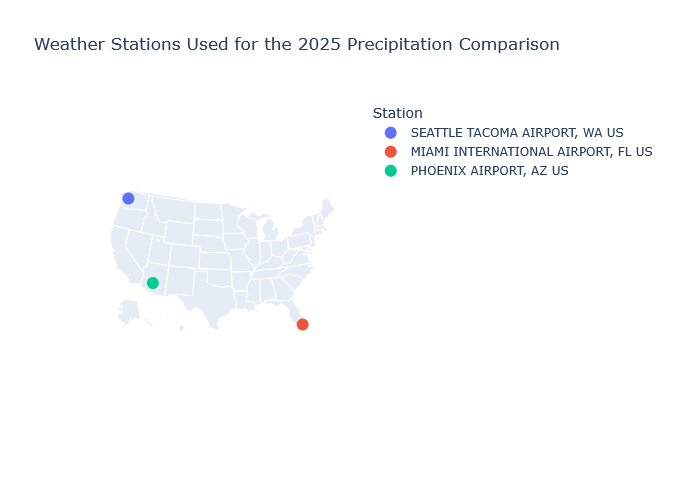

In [28]:
station_locations_df = weather_df[
    ["STATION", "NAME", "LATITUDE", "LONGITUDE"]
].drop_duplicates()

fig = px.scatter_geo(
    station_locations_df,
    lat="LATITUDE",
    lon="LONGITUDE",
    color="NAME",
    hover_name="NAME",
    hover_data=["STATION"],
    scope="usa",
    title="Weather Stations Used for the 2025 Precipitation Comparison"
)

fig.update_traces(marker=dict(size=12))
fig.update_layout(height=500, legend_title_text="Station")
fig.show()
color_discrete_map=station_colors,

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer:Figure 1 shows the three airport stations used for the January–December 2025 precipitation comparison: Seattle–Tacoma in the northwestern United States, Phoenix in the Southwest, and Miami in the Southeast. For example, Seattle–Tacoma is located at approximately 47.44° N, 122.31° W. Each equal-sized marker represents one station, for three stations total; marker size does not represent precipitation. The map establishes where observations were collected but does not show monthly precipitation changes.

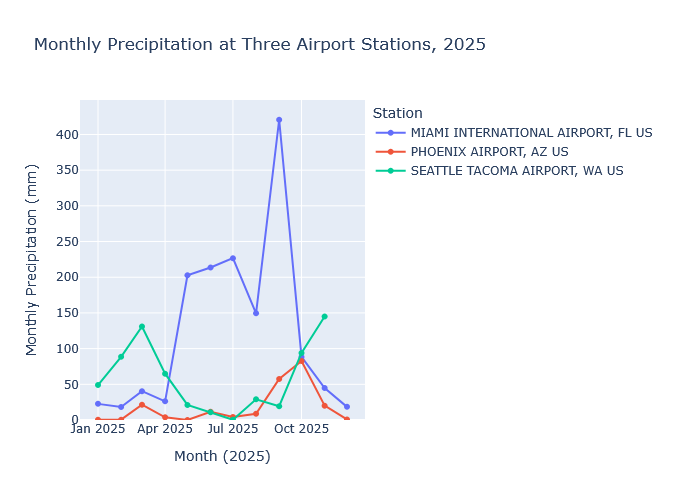

In [29]:
fig = px.line(
    weather_monthly_df.sort_values(["STATION", "month"]),
    x="month",
    y="precipitation_mm",
    color="NAME",
    markers=True,
    hover_data=["observed_days", "expected_days"],
    labels={
        "month": "Month (2025)",
        "precipitation_mm": "Monthly Precipitation (mm)",
        "NAME": "Station"
    },
    title="Monthly Precipitation at Three Airport Stations, 2025"
)

fig.update_traces(connectgaps=False)
fig.update_yaxes(rangemode="tozero")
fig.update_layout(height=500)
fig.show()
color_discrete_map=station_colors,

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer:Figure 2 shows different monthly precipitation patterns among the three stations during 2025. Miami recorded 420.6 mm in September, compared with 57.5 mm in Phoenix and 19.3 mm in Seattle–Tacoma that month. Seattle–Tacoma recorded only 0.3 mm in July but 144.9 mm in November. Phoenix’s highest monthly total was 82.7 mm in October.

Figure 1 establishes the stations’ geographic locations, while Figure 2 shows when and by how much precipitation differed. Seattle’s December point is absent because one daily measurement was missing; it does not indicate zero precipitation.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [30]:
checks = [
    ("USW00012839", "2025-09"),
    ("USW00023183", "2025-10")
]

for station, month in checks:
    daily = weather_analysis_df.loc[
        (weather_analysis_df["STATION"] == station)
        & (weather_analysis_df["month"] == month),
        "usable_prcp"
    ]

    plotted = weather_monthly_df.loc[
        (weather_monthly_df["STATION"] == station)
        & (weather_monthly_df["month"] == month),
        "precipitation_mm"
    ].iloc[0]

    print(station, month)
    print("Daily sum:", round(daily.sum(min_count=1), 1))
    print("Chart total:", round(plotted, 1))

print("Months ordered within each station:")
display(
    weather_monthly_df.groupby("STATION")["month"]
    .apply(lambda months: months.is_monotonic_increasing)
)

print("Station coordinates:")
display(station_locations_df)

print("Incomplete month:")
display(
    weather_monthly_df.loc[
        ~weather_monthly_df["complete_month"],
        ["NAME", "month", "observed_days",
         "expected_days", "precipitation_mm"]
    ]
)

USW00012839 2025-09
Daily sum: 420.6
Chart total: 420.6
USW00023183 2025-10
Daily sum: 82.7
Chart total: 82.7
Months ordered within each station:


STATION
USW00012839    True
USW00023183    True
USW00024233    True
Name: month, dtype: bool

Station coordinates:


,STATION,NAME,LATITUDE,LONGITUDE
0,USW00024233,"SEATTLE TACOMA AIRPORT, WA US",47.44467,-122.31442
365,USW00012839,"MIAMI INTERNATIONAL AIRPORT, FL US",25.78805,-80.31694
730,USW00023183,"PHOENIX AIRPORT, AZ US",33.42780,-112.00365


Incomplete month:


,NAME,month,observed_days,expected_days,precipitation_mm
35,"SEATTLE TACOMA AIRPORT, WA US",2025-12,30,31,NaN


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer:I checked Miami’s September total of 420.6 mm and Phoenix’s October total of 82.7 mm by recalculating them from daily measurements. Both matched the monthly summaries used in the chart. Months were in chronological order within all three stations, and the station coordinates were consistent with their mapped locations.

I also checked Seattle’s absent December point. Only 30 of 31 days had usable measurements, so the monthly total correctly remained missing rather than appearing as zero. Miami’s September peak was supported by its daily sum, rather than caused by incorrect month ordering.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer:My question was how monthly precipitation differed among the Seattle–Tacoma, Miami, and Phoenix airport stations during 2025. The map places these stations in the Northwest, Southeast, and Southwest, respectively. The line chart shows different timing and amounts: in September, Miami recorded 420.6 mm, Phoenix 57.5 mm, and Seattle–Tacoma 19.3 mm. Seattle–Tacoma increased from 0.3 mm in July to 144.9 mm in November, while Phoenix reached its highest monthly total of 82.7 mm in October. These findings show that both location and month mattered in this year’s records.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:First, three airport stations during one year do not represent entire cities, regions, or long-term climate patterns. Monthly totals also hide daily extremes, and trace amounts have limited numerical precision.

Second, Seattle’s missing daily measurement prevents a complete December total. The map shows station locations but does not encode precipitation amounts or timing. The line chart makes monthly comparisons easier but provides little geographic context and cannot reveal precipitation between stations. Neither figure establishes causes for the observed differences.


## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:I used ChatGPT to help find data sources, explain Python code, create Plotly figures. One suggestion I checked was to leave Seattle’s December precipitation total missing rather than treating the missing daily measurement as zero. My output confirmed that only 30 of 31 days had usable measurements, so I accepted this approach. I also recalculated Miami’s September total of 420.6 mm and Phoenix’s October total of 82.7 mm from daily records and confirmed they matched the monthly summaries used in the chart.

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.